# **Data exploration**


In [18]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Find the project folder
project_dir = Path.cwd()
if not (project_dir / "data").exists():
    project_dir = project_dir.parent
    
# Locate the CSV
csv_path = project_dir / "data/processed/freshretailnet_train.csv"

# Load the data
df = pd.read_csv(csv_path)

print("Dataset shape:", df.shape)

display(df.head())


Dataset shape: (4500000, 65)


,time,city_id,store_id,management_group_id,first_category_id,second_category_id,third_category_id,product_id,sale_amount,stock_hour6_22_cnt,...,hours_stock_status_14,hours_stock_status_15,hours_stock_status_16,hours_stock_status_17,hours_stock_status_18,hours_stock_status_19,hours_stock_status_20,hours_stock_status_21,hours_stock_status_22,hours_stock_status_23
0,1711584000000,0,0,0,28,72,154,834,0.9,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1711670400000,0,0,0,28,72,154,834,2.0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1711756800000,0,0,0,28,72,154,834,1.9,9,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
3,1711843200000,0,0,0,28,72,154,834,1.1,12,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
4,1711929600000,0,0,0,28,72,154,834,1.3,7,...,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 1. First Data Inspection

In [19]:

# Inspect all column names
print("DATASET COLUMNS:\n")

for i, col in enumerate(df.columns):
    print(f"{i}: {col}")

# Count stores, products, and dates
print("\nDATASET STRUCTURE:")

print("Unique stores:", df["store_id"].nunique())
print("Unique products:", df["product_id"].nunique())

print("Unique timestamps:", df["time"].nunique())

# Convert timestamps to dates for inspection
df["date"] = pd.to_datetime(df["time"], unit="ms")

print("\nDate range:")
print(df["date"].min())
print(df["date"].max())


DATASET COLUMNS:

0: time
1: city_id
2: store_id
3: management_group_id
4: first_category_id
5: second_category_id
6: third_category_id
7: product_id
8: sale_amount
9: stock_hour6_22_cnt
10: discount
11: holiday_flag
12: activity_flag
13: precpt
14: avg_temperature
15: avg_humidity
16: avg_wind_level
17: hours_sale_00
18: hours_sale_01
19: hours_sale_02
20: hours_sale_03
21: hours_sale_04
22: hours_sale_05
23: hours_sale_06
24: hours_sale_07
25: hours_sale_08
26: hours_sale_09
27: hours_sale_10
28: hours_sale_11
29: hours_sale_12
30: hours_sale_13
31: hours_sale_14
32: hours_sale_15
33: hours_sale_16
34: hours_sale_17
35: hours_sale_18
36: hours_sale_19
37: hours_sale_20
38: hours_sale_21
39: hours_sale_22
40: hours_sale_23
41: hours_stock_status_00
42: hours_stock_status_01
43: hours_stock_status_02
44: hours_stock_status_03
45: hours_stock_status_04
46: hours_stock_status_05
47: hours_stock_status_06
48: hours_stock_status_07
49: hours_stock_status_08
50: hours_stock_status_09
51: ho

## 2. Inspect an individual product's sale

In [20]:

# Count observations for each store-product combination
series_counts = (
    df.groupby(["store_id", "product_id"])
      .agg(
          n_days=("date", "nunique"),
          total_sales=("sale_amount", "sum")
      )
      .reset_index()
)

print("Number of store-product combinations:", len(series_counts))

print("\nDistribution of days per combination:")
display(series_counts["n_days"].describe())

print("\nNumber with all 90 days:")
print((series_counts["n_days"] == 90).sum())

# Show combinations with the most observations
display(
    series_counts.sort_values(
        ["n_days", "total_sales"],
        ascending=False
    ).head(10)
)


Number of store-product combinations: 50000

Distribution of days per combination:


count    50000.0
mean        90.0
std          0.0
min         90.0
25%         90.0
50%         90.0
75%         90.0
max         90.0
Name: n_days, dtype: float64


Number with all 90 days:
50000


,store_id,product_id,n_days,total_sales
2817,50,267,90,1716.7
6722,122,267,90,1715.1
4829,87,267,90,1703.8
34250,547,267,90,1702.7
433,5,267,90,1694.4
49802,894,267,90,1694.4
31151,496,267,90,1689.3
28537,453,267,90,1680.3
22050,339,267,90,1675.1
40911,675,267,90,1667.9


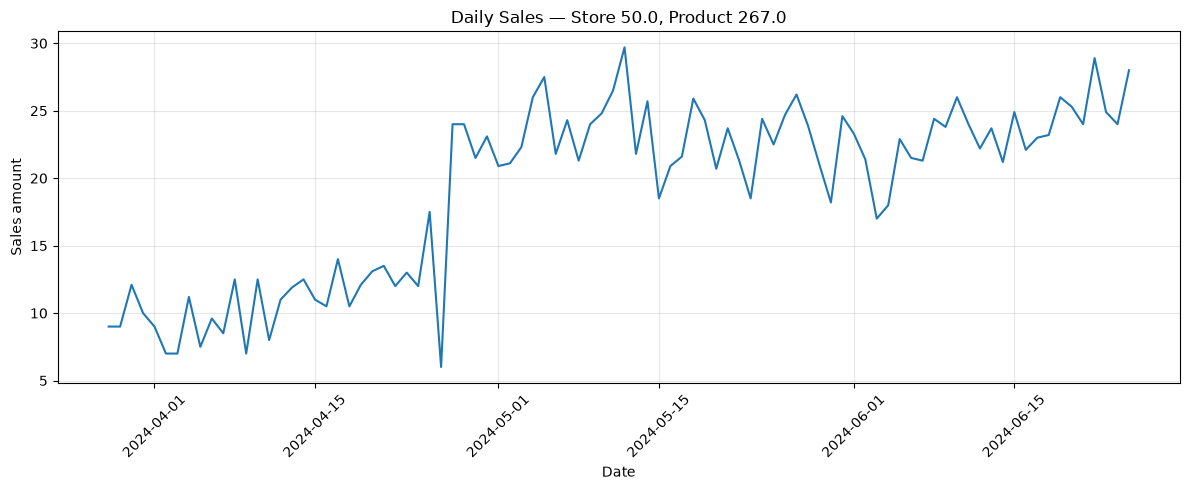

In [21]:

# Select a store-product series with the most observations
selected = series_counts.sort_values(
    ["n_days", "total_sales"],
    ascending=False
).iloc[0]

store = selected["store_id"]
product = selected["product_id"]

# Filter the selected series
product_data = df[
    (df["store_id"] == store) &
    (df["product_id"] == product)
].copy()

# Aggregate in case multiple rows share a date
daily_sales = (
    product_data.groupby("date")["sale_amount"]
    .sum()
    .sort_index()
)

# Plot daily sales
plt.figure(figsize=(12, 5))
plt.plot(daily_sales.index, daily_sales.values)

plt.title(f"Daily Sales — Store {store}, Product {product}")
plt.xlabel("Date")
plt.ylabel("Sales amount")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
